# Ten Sentinel-2 tiles on HEALPix — 60 m overview and spectral validation against UTM

Stores: `s3://grid4earth/test-compression/s2_ten_tiles/<site>/healpix.zarr`, whole L2A products converted to HEALPix (reflectance at level 20 for the 10 m bands, 19 for 20 m, 17 for 60 m), reflectance under the `hcc-sentinel2-pyramid` codec. The conversion is still running for some tiles: the notebook works on whatever is already written and can be re-run as tiles complete.

1. **Status** of the ten tiles (complete or in progress, chunks written).
2. **60 m overview**: B04/B03/B02 composite of each tile from the level-17 reflectance (60 m bands), shown on the tile's own UTM 60 m grid. For tiles whose level 17 is not written yet, the level-20 cells are averaged to level 17 (64 children per cell).
3. **Spectral validation** on `N_PATCHES` random patches of `PATCH`×`PATCH` pixels of the 10 m bands per tile. For each patch three radial power spectra are computed:
   - **UTM**: the L2A source patch;
   - **UTM − UTM from HEALPix**: the source minus the HEALPix field reprojected onto the same UTM pixels with `healpix_resample.PSFResampler.invert` (the conversion's own observation model and parameters);
   - **HEALPix (tangent plane)**: the compressed HEALPix cells themselves, over a patch of the same centre and the same area. Around a patch the nested HEALPix cells form a regular grid in face indices (ix, iy), which is an affine grid in the plane tangent to the patch centre. The FFT is taken directly on that index grid (no interpolation), and its frequencies are mapped to physical frequencies by the fitted affine transform.

   The spectra of all patches of a tile are drawn on the same panel, one colour per kind; bands are rows and tiles are columns.

All values are **surface reflectance**; spectra are in reflectance²·km² (the integral of the 2D PSD over the frequency plane is the variance). Run with the **Python (venv-hc)** kernel under WSL (AWS profile `default`, OVH GRA endpoint). A first full run (10 patches × 10 tiles) takes about half an hour, most of it for the 60 m overview of the tiles still running; the overview and the spectra of finished tiles are cached in `CACHE_DIR` and not recomputed.

In [1]:
# ---- parameters ------------------------------------------------------------------------
ROOT = "grid4earth/test-compression/s2_ten_tiles"
SITES = ["paris_urban", "alps_mountain_snow", "andalusia_agriculture", "landes_forest",
         "almeria_arid_greenhouses", "brittany_coast_sea", "rotterdam_port_delta",
         "iceland_volcanic_glacier", "camargue_wetlands", "finland_boreal_lakes"]
N_PATCHES = 10          # number of test patches per tile
PATCH = 256            # patch size in 10 m UTM pixels
SEED = 0               # patch positions are reproducible for a given seed
MAX_FILL = 0.001       # largest share of UTM pixels at the fill value (DN 0) accepted in a patch
BANDS = ["b02", "b03", "b04", "b08"]
FALLBACK_FROM_L20 = True   # 60 m overview of tiles without level 17 yet: average level 20 (slower)
WORKERS = 16
CACHE_DIR = "~/.cache/hpx_ten_tiles"

In [2]:
import sys, json, time, pickle, logging, functools, threading
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

# The healpix-compress repo has its own `hcc/` folder: import the healpix-compress-s2 package
# (which provides the hcc-sentinel2-pyramid codec) instead.
sys.path = [p for p in sys.path if not p.rstrip("/").endswith("healpix-compress")]
import hcc
assert "healpix-compress-s2" in hcc.__file__, hcc.__file__

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
import pyproj, s3fs, torch, zarr, zarr.storage
from zarr.registry import register_codec
from hcc.codecs.sentinel2_pyramid import HccSentinel2PyramidCodec
from healpix_geo.nested import lonlat_to_healpix, healpix_to_lonlat
from healpix_resample.psf import PSFResampler

register_codec("hcc-sentinel2-pyramid", HccSentinel2PyramidCodec)
logging.getLogger("asyncio").setLevel(logging.CRITICAL)
import warnings; warnings.filterwarnings("ignore", category=UserWarning, module="healpix_resample")
torch.set_num_threads(8)
plt.rcParams.update({"figure.dpi": 72, "image.interpolation": "nearest"})

EP = dict(profile="default", endpoint_url="https://s3.gra.io.cloud.ovh.net", client_kwargs={"region_name": "gra"})
fs = s3fs.S3FileSystem(skip_instance_cache=True, **EP)
afs = s3fs.S3FileSystem(asynchronous=True, **EP)
open_arr = lambda p: zarr.open_array(zarr.storage.FsspecStore(afs, path=p, read_only=True), mode="r")
CACHE = Path(CACHE_DIR).expanduser(); CACHE.mkdir(parents=True, exist_ok=True)
DX, MARGIN = 10.0, 8
print("torch", torch.__version__, "| cuda:", torch.cuda.is_available())

torch 2.14.1+cpu | cuda: False


## 1. Status of the ten tiles

For each tile: the source product, whether the conversion is finished (`DONE` marker), and the share of level-20 chunks already written for all four 10 m bands. The chunk count includes edge chunks that the conversion skips when the tile has no data there, so a finished tile can stay slightly below 100 %.

In [3]:
def written(group, names):
    keys = None
    for a in names:
        try:
            k = {int(x.rsplit("/", 1)[1]) for x in fs.ls(f"{group}/{a}/c", refresh=True)}
        except FileNotFoundError:
            k = set()
        keys = k if keys is None else keys & k
    return keys

class ChunkIndex:
    # parent level-11 cell -> chunk position, by binary search on a sorted cell_ids array
    def __init__(self, cid, level):
        self.cid, self.cs, self.n, self.shift = cid, cid.chunks[0], cid.nchunks, np.uint64(2 * (level - 11))
        self.cache, self.lock = {}, threading.Lock()
    def parent(self, i):
        if i not in self.cache:
            v = int(self.cid[i * self.cs] >> self.shift)
            with self.lock:
                self.cache[i] = v
        return self.cache[i]
    def find(self, p):
        lo, hi = 0, self.n - 1
        while lo <= hi:
            mid = (lo + hi) // 2
            v = self.parent(mid)
            if v == p:
                return mid
            lo, hi = (mid + 1, hi) if v < p else (lo, mid - 1)
        return None

info = {}
print(f"{'site':26s}{'product':64s}{'state':>8s}{'L20 chunks':>16s}{'L17':>6s}")
for site in SITES:
    base = f"{ROOT}/{site}"
    try:
        files = {p.rsplit("/", 1)[1] for p in fs.ls(base, refresh=True)}
    except FileNotFoundError:
        print(f"{site:26s}not started"); continue
    g20 = f"{base}/healpix.zarr/measurements/reflectance/20"
    if "mirror.json" not in files or not fs.exists(f"{g20}/cell_ids/zarr.json"):
        print(f"{site:26s}{'(no level-20 output yet)':64s}"); continue
    mirror = json.loads(fs.cat(f"{base}/mirror.json"))
    root_meta = json.loads(fs.cat(f"{base}/healpix.zarr/zarr.json"))
    props = root_meta.get("attributes", {}).get("stac_discovery", {}).get("properties", {})
    try:
        res = props["processing:expression"]["expression"]["group_settings"]["measurements/reflectance/r10m"]["resampler"]
        init = dict(res.get("init_params", {}))
    except KeyError:
        init = {}
    init = {"Npt": init.get("Npt", 9), "threshold": init.get("threshold", 0.1)}
    g17 = f"{base}/healpix.zarr/measurements/reflectance/17"
    has17 = fs.exists(f"{g17}/cell_ids/zarr.json")
    cid20 = open_arr(f"{g20}/cell_ids")
    I = dict(site=site, product=mirror["product"], href=mirror["href"], done="DONE" in files,
             epsg=props.get("proj:code", "EPSG:32631"), init=init, g20=g20, g17=g17,
             w20=written(g20, ["cell_ids"] + BANDS), nch=cid20.nchunks,
             w17=written(g17, ["cell_ids", "b02", "b03", "b04"]) if has17 else set())
    I["index"] = ChunkIndex(open_arr(f"{g17}/cell_ids"), 17) if I["w17"] else ChunkIndex(cid20, 20)
    info[site] = I
    print(f"{site:26s}{I['product']:64s}{'DONE' if I['done'] else 'running':>8s}"
          f"{len(I['w20']):>7d}/{I['nch']:<5d}{100 * len(I['w20']) / I['nch']:4.0f}%{'yes' if I['w17'] else 'no':>6s}")
print("\nPSF resampler parameters (from the stores):", {s: info[s]["init"] for s in info})

site                      product                                                            state      L20 chunks   L17


paris_urban               S2B_MSIL2A_20260812T104619_N0512_R051_T31UDQ_20260812T131957        DONE   1276/1277  100%   yes


alps_mountain_snow        S2A_MSIL2A_20260724T102701_N0512_R108_T32TLR_20260724T171410        DONE   1292/1292  100%   yes


andalusia_agriculture     S2B_MSIL2A_20260530T110619_N0512_R137_T30STG_20260530T145841        DONE   1287/1288  100%   yes


landes_forest             S2B_MSIL2A_20260914T105619_N0512_R094_T30TXP_20260914T152429        DONE   1292/1292  100%   yes


...

brittany_coast_sea        S2B_MSIL2A_20260811T112109_N0512_R037_T30UUU_20260811T134112     running   1289/1289  100%    no


rotterdam_port_delta      S2A_MSIL2A_20260501T104651_N0512_R051_T31UET_20260501T173800     running   1285/1285  100%    no


iceland_volcanic_glacier  S2A_MSIL2A_20260520T130311_N0512_R038_T27VWL_20260520T204616     running   1290/1292  100%    no


camargue_wetlands         S2B_MSIL2A_20260627T102559_N0512_R108_T31TFJ_20260627T142435     running   1277/1290   99%    no


finland_boreal_lakes      S2A_MSIL2A_20260907T094121_N0512_R036_T35VNK_20260907T142210     running   1296/1296  100%    no

PSF resampler parameters (from the stores): {'paris_urban': {'Npt': 9, 'threshold': 0.1}, 'alps_mountain_snow': {'Npt': 9, 'threshold': 0.1}, 'andalusia_agriculture': {'Npt': 9, 'threshold': 0.1}, 'landes_forest': {'Npt': 9, 'threshold': 0.1}, 'almeria_arid_greenhouses': {'Npt': 9, 'threshold': 0.1}, 'brittany_coast_sea': {'Npt': 9, 'threshold': 0.1}, 'rotterdam_port_delta': {'Npt': 9, 'threshold': 0.1}, 'iceland_volcanic_glacier': {'Npt': 9, 'threshold': 0.1}, 'camargue_wetlands': {'Npt': 9, 'threshold': 0.1}, 'finland_boreal_lakes': {'Npt': 9, 'threshold': 0.1}}


## 2. 60 m overview

Each tile is shown on its own UTM grid at 60 m (1830 × 1830 pixels): every pixel takes the value of the level-17 HEALPix cell (about 49 m) that contains its centre. All tiles share one contrast stretch, given by the colour bar (the same range is applied to each of the R, G and B channels). Grey areas have no HEALPix data written yet, or lie outside the tile's data.

paris_urban                level 17                 coverage 100.0%  (0s)
alps_mountain_snow         level 17                 coverage 100.0%  (0s)
andalusia_agriculture      level 17                 coverage 100.0%  (0s)
landes_forest              level 17                 coverage 100.0%  (0s)
almeria_arid_greenhouses   level 17                 coverage  99.1%  (0s)


brittany_coast_sea         level 20 averaged to 17  coverage 100.0%  (165s)


rotterdam_port_delta       level 20 averaged to 17  coverage 100.0%  (354s)


iceland_volcanic_glacier   level 20 averaged to 17  coverage 100.0%  (556s)


camargue_wetlands          level 20 averaged to 17  coverage  99.5%  (742s)


finland_boreal_lakes       level 20 averaged to 17  coverage 100.0%  (935s)


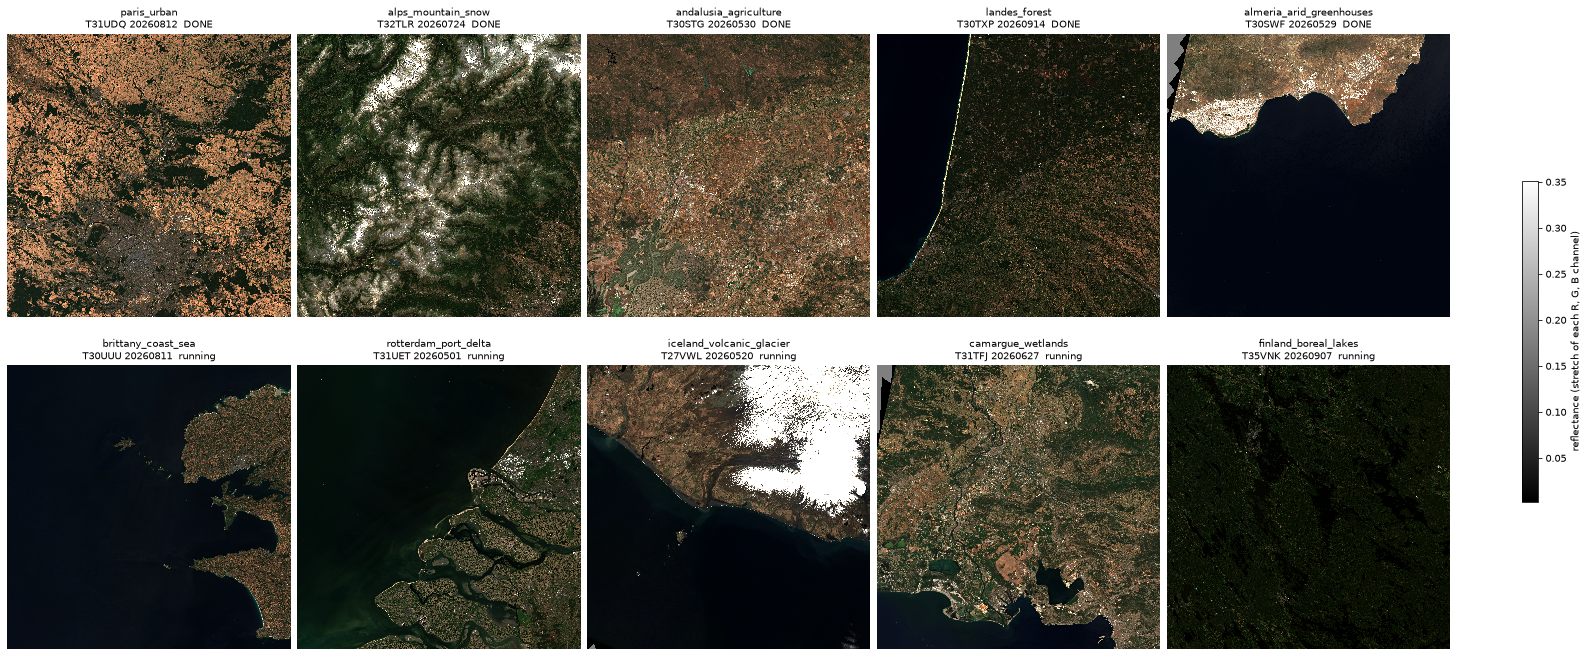

In [4]:
class Utm:
    # the source product's 10 m group, read directly from the EOPF service
    cache = {}
    @classmethod
    def get(cls, site):
        if site not in cls.cache:
            I = info[site]
            g = zarr.open_group(zarr.storage.FsspecStore.from_url(I["href"] + "/measurements/reflectance/r10m",
                                                                  read_only=True), mode="r")
            a = g["b04"].attrs
            cls.cache[site] = dict(group=g, x=g["x"][:], y=g["y"][:], scale=float(a["scale_factor"]),
                                   offset=float(a["add_offset"]),
                                   to_wgs=pyproj.Transformer.from_crs(I["epsg"], 4326, always_xy=True))
        return cls.cache[site]

def chunk_slice(arr, i):
    return arr[i * arr.chunks[0]:(i + 1) * arr.chunks[0]]

def level17_rgb(site):
    I = info[site]
    if I["w17"]:
        chunks = sorted(I["w17"])
        arrs = [open_arr(f"{I['g17']}/{a}") for a in ("cell_ids", "b04", "b03", "b02")]
        with ThreadPoolExecutor(WORKERS) as ex:
            parts = [list(ex.map(lambda c: chunk_slice(a, c), chunks)) for a in arrs]
        cells = np.concatenate(parts[0]); vals = np.stack([np.concatenate(p) for p in parts[1:]])
        src = "level 17"
    elif FALLBACK_FROM_L20 and I["w20"]:
        chunks = sorted(I["w20"])
        bands = [open_arr(f"{I['g20']}/{b}") for b in ("b04", "b03", "b02")]
        def one(c):
            p = I["index"].parent(c)
            v = np.stack([np.nanmean(chunk_slice(a, c).reshape(4096, 64), axis=1) for a in bands])
            return (np.uint64(p) << np.uint64(12)) + np.arange(4096, dtype=np.uint64), v
        with ThreadPoolExecutor(WORKERS) as ex:
            out = list(ex.map(one, chunks))
        cells = np.concatenate([o[0] for o in out]); vals = np.concatenate([o[1] for o in out], axis=1)
        src = "level 20 averaged to 17"
    else:
        return None
    o = np.argsort(cells); cells, vals = cells[o], vals[:, o]
    U = Utm.get(site)
    x60 = U["x"][0] - 5 + 30 + 60 * np.arange(U["x"].size // 6)
    y60 = U["y"][0] + 5 - 30 - 60 * np.arange(U["y"].size // 6)
    XX, YY = np.meshgrid(x60, y60)
    lon, lat = U["to_wgs"].transform(XX, YY)
    hc = np.asarray(lonlat_to_healpix(lon.ravel(), lat.ravel(), 17, ellipsoid="WGS84")).astype(np.uint64)
    pos = np.minimum(np.searchsorted(cells, hc), cells.size - 1)
    hit = cells[pos] == hc
    img = np.full((3, hc.size), np.nan, np.float32)
    img[:, hit] = vals[:, pos[hit]]
    img[img == 0] = np.nan                                   # fill value of the codec
    return dict(img=img.reshape(3, *XX.shape), src=src, coverage=hit.mean())

def cached_level17_rgb(site):
    cf = CACHE / f"{site}_overview60m.pkl"
    if info[site]["done"] and cf.exists():
        return pickle.loads(cf.read_bytes())
    r = level17_rgb(site)
    if r is not None:
        r["img"] = r["img"].astype(np.float16)
        if info[site]["done"]:
            cf.write_bytes(pickle.dumps(r))
    return r

t = time.time()
overview = {}
for site in info:
    r = cached_level17_rgb(site)
    if r is not None:
        overview[site] = r
        print(f"{site:26s} {r['src']:24s} coverage {100 * r['coverage']:5.1f}%  ({time.time() - t:.0f}s)")
pool = np.concatenate([o["img"][:, ::7, ::7].reshape(3, -1).astype(np.float32) for o in overview.values()], axis=1)
LO, HI = np.nanpercentile(pool, [2, 98])

def rgb(img):
    out = np.clip((np.moveaxis(img.astype(np.float32), 0, -1) - LO) / (HI - LO), 0, 1)
    return np.where(np.isnan(out), 0.5, out)

def show_overview(boxes=None):
    sites = list(overview)
    nc = 5; nr = -(-len(sites) // nc)
    fig, ax = plt.subplots(nr, nc, figsize=(4.4 * nc, 4.6 * nr), constrained_layout=True, squeeze=False)
    for a in ax.flat:
        a.set_axis_off()
    for a, site in zip(ax.flat, sites):
        a.imshow(rgb(overview[site]["img"]))
        a.set_title(f"{site}\n{info[site]['product'][38:44]} {info[site]['product'][11:19]}  "
                    f"{'DONE' if info[site]['done'] else 'running'}", fontsize=10)
        for (i0, j0) in (boxes or {}).get(site, []):
            a.add_patch(Rectangle((j0 / 6, i0 / 6), PATCH / 6, PATCH / 6, fill=False, ec="yellow", lw=1.2))
    fig.colorbar(ScalarMappable(Normalize(LO, HI), "gray"), ax=ax, shrink=0.5, label="reflectance (stretch of each R, G, B channel)")
    plt.show()

show_overview()

## 3. Spectral validation on 10 m patches

For each tile, patch positions are drawn at random (reproducible with `SEED`) inside the UTM tile. A patch is kept when all the HEALPix chunks it needs are written and at most a share `MAX_FILL` of its UTM pixels are at the fill value (DN 0, which also occurs as isolated pixels on very dark lakes); the draw goes on until `N_PATCHES` patches are kept. Those few pixels are treated as missing: set to the patch mean for the FFT and left out of the RMS.

For each kept patch and band:
- the UTM patch is read from the EOPF product and converted to reflectance;
- the HEALPix cells of all level-11 chunks touching the patch are read (compressed field);
- `PSFResampler` is built on the patch pixel centres with the conversion's parameters, and `invert` gives the UTM pixels predicted by the HEALPix field;
- for the tangent-plane spectrum, the face indices (ix, iy) of the cell at the patch centre are taken, an affine map from (ix, iy) to an azimuthal equidistant plane centred on the patch is fitted on the surrounding cells, and the square of S × S cells whose area equals the UTM patch area is used.

Spectra are binned on common logarithmic frequency bins. Tiles that are finished are cached in `CACHE_DIR`.

In [5]:
EDGES = np.logspace(np.log10(0.3), np.log10(130.0), 56)          # cycles/km
KC = np.sqrt(EDGES[1:] * EDGES[:-1])

def binned(kr, psd2):
    idx = np.digitize(kr.ravel(), EDGES) - 1
    ok = (idx >= 0) & (idx < KC.size)
    s = np.bincount(idx[ok], psd2.ravel()[ok], minlength=KC.size)
    n = np.bincount(idx[ok], minlength=KC.size)
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.where(n > 0, s / n, np.nan)

def hann_fft(img):
    a = np.array(img, float)
    a = np.where(np.isnan(a), np.nanmean(a), a)                          # missing pixels -> patch mean
    a -= a.mean()
    n0, n1 = a.shape
    w = np.outer(np.hanning(n0), np.hanning(n1))
    return np.abs(np.fft.fft2(a * w)) ** 2 / (n0 * n1 * np.mean(w ** 2))

def psd_regular(img, dx=DX):
    # radial PSD of a field on a regular grid of step dx (m), in refl² km²
    p = hann_fft(img) * dx * dx / 1e6
    f = np.fft.fftfreq(img.shape[0], d=dx) * 1e3
    return binned(np.hypot(*np.meshgrid(f, f, indexing="ij")), p)

def psd_affine(img, A):
    # radial PSD of a field on an affine grid x = A @ (i, j) (metres), in refl² km²
    p = hann_fft(img) * abs(np.linalg.det(A)) / 1e6
    q = np.fft.fftfreq(img.shape[0])                                    # cycles per index
    Q = np.stack(np.meshgrid(q, q, indexing="ij"))                      # (2, S, S)
    K = np.einsum("ab,bij->aij", np.linalg.inv(A).T, Q) * 1e3           # cycles/km
    return binned(np.hypot(K[0], K[1]), p)

def spread(v):
    v = v.astype(np.uint64) & np.uint64(0xFFFFFFFF)
    for s, m in ((16, 0x0000FFFF0000FFFF), (8, 0x00FF00FF00FF00FF), (4, 0x0F0F0F0F0F0F0F0F),
                 (2, 0x3333333333333333), (1, 0x5555555555555555)):
        v = (v | (v << np.uint64(s))) & np.uint64(m)
    return v

def compact(v):
    v = v & np.uint64(0x5555555555555555)
    for s, m in ((1, 0x3333333333333333), (2, 0x0F0F0F0F0F0F0F0F), (4, 0x00FF00FF00FF00FF),
                 (8, 0x0000FFFF0000FFFF), (16, 0x00000000FFFFFFFF)):
        v = (v | (v >> np.uint64(s))) & np.uint64(m)
    return v

NSIDE2 = np.uint64(4 ** 20)

def tangent_square(lon0, lat0):
    # nested ids of the S x S square of face indices around (lon0, lat0) with the patch's area, and its affine map
    c0 = np.asarray(lonlat_to_healpix(np.array([lon0]), np.array([lat0]), 20, ellipsoid="WGS84")).astype(np.uint64)[0]
    face, loc = c0 // NSIDE2, c0 % NSIDE2
    ix0, iy0 = int(compact(loc)), int(compact(loc >> np.uint64(1)))
    d = np.arange(-40, 41, 10)
    DI, DJ = [v.ravel() for v in np.meshgrid(d, d, indexing="ij")]
    ids = face * NSIDE2 + spread(ix0 + DI) + (spread(iy0 + DJ) << np.uint64(1))
    lo, la = healpix_to_lonlat(ids, 20, ellipsoid="WGS84")
    aeqd = pyproj.Transformer.from_crs(4326, pyproj.CRS.from_proj4(
        f"+proj=aeqd +lat_0={lat0} +lon_0={lon0} +ellps=WGS84 +units=m"), always_xy=True)
    X, Y = aeqd.transform(np.asarray(lo), np.asarray(la))
    D = np.stack([DI, DJ, np.ones_like(DI)], axis=1).astype(float)
    coef = np.linalg.lstsq(D, np.stack([X, Y], axis=1), rcond=None)[0]
    A = coef[:2].T                                                      # x = A @ (di, dj)
    S = int(round(PATCH * DX / np.sqrt(abs(np.linalg.det(A)))))
    di = np.arange(S) - S // 2
    IX, IY = ix0 + di[:, None], iy0 + di[None, :]
    if IX.min() < 0 or IY.min() < 0 or max(IX.max(), IY.max()) >= 2 ** 20:
        return None
    sq = face * NSIDE2 + spread(np.broadcast_to(IX, (S, S))) + (spread(np.broadcast_to(IY, (S, S))) << np.uint64(1))
    return sq, A

def process_patch(site, i0, j0):
    I, U = info[site], Utm.get(site)
    xs, ys = U["x"][j0 - MARGIN:j0 + PATCH + MARGIN], U["y"][i0 - MARGIN:i0 + PATCH + MARGIN]
    XX, YY = np.meshgrid(xs, ys)
    LON, LAT = U["to_wgs"].transform(XX, YY)
    lon0, lat0 = U["to_wgs"].transform(U["x"][j0 + PATCH // 2] - 5, U["y"][i0 + PATCH // 2] + 5)
    tq = tangent_square(lon0, lat0)
    if tq is None:
        return None, "tangent square crosses a HEALPix face boundary"
    sq, A = tq
    par = np.unique(np.concatenate([np.asarray(lonlat_to_healpix(LON.ravel(), LAT.ravel(), 11, ellipsoid="WGS84")).astype(np.uint64),
                                    sq.ravel() >> np.uint64(18)]))
    chunks = [I["index"].find(int(p)) for p in par]
    if any(c is None or c not in I["w20"] for c in chunks):
        return None, "HEALPix chunks not written"
    with ThreadPoolExecutor(4) as ex:
        dn = np.stack(list(ex.map(lambda b: U["group"][b][i0:i0 + PATCH, j0:j0 + PATCH], BANDS))).astype(float)
    if (dn == 0).mean() > MAX_FILL:
        return None, "UTM fill"
    utm = np.where(dn == 0, np.nan, dn * U["scale"] + U["offset"])      # isolated DN 0 (e.g. dark lakes) -> missing
    arrs = [open_arr(f"{I['g20']}/{a}") for a in ["cell_ids"] + BANDS]
    with ThreadPoolExecutor(8) as ex:
        parts = list(ex.map(lambda ac: chunk_slice(*ac), [(a, c) for a in arrs for c in chunks]))
    n = len(chunks)
    cells = np.concatenate(parts[:n]); vals = np.stack([np.concatenate(parts[n * (k + 1):n * (k + 2)]) for k in range(len(BANDS))])
    o = np.argsort(cells); cells, vals = cells[o], vals[:, o]
    inner = (slice(MARGIN, -MARGIN), slice(MARGIN, -MARGIN))
    R = PSFResampler(LON[inner].ravel(), LAT[inner].ravel(), level=20, device="cpu", dtype=torch.float64,
                     verbose=False, **I["init"])
    rc = R.cell_ids.cpu().numpy().astype(np.uint64)
    pr = np.minimum(np.searchsorted(cells, rc), cells.size - 1)
    if not np.all(cells[pr] == rc):
        return None, "PSF needs cells outside the loaded chunks"
    rec = R.invert(vals[:, pr]).reshape(len(BANDS), PATCH, PATCH)
    del R
    ps = np.minimum(np.searchsorted(cells, sq.ravel()), cells.size - 1)
    if not np.all(cells[ps] == sq.ravel()):
        return None, "tangent square cells missing"
    hpx = vals[:, ps].reshape(len(BANDS), *sq.shape)
    diff = utm - rec
    spec = np.stack([[psd_regular(utm[b]), psd_regular(diff[b]), psd_affine(hpx[b], A)] for b in range(len(BANDS))])
    return dict(i0=i0, j0=j0, lon0=lon0, lat0=lat0, spec=spec, S=sq.shape[0], cell_m=float(np.sqrt(abs(np.linalg.det(A)))),
                rms=np.sqrt(np.nanmean(diff ** 2, axis=(1, 2))), std=np.nanstd(utm, axis=(1, 2)),
                mean=np.nanmean(utm, axis=(1, 2)), fill=float(np.isnan(utm).mean()),
                hpx_std=hpx.std(axis=(1, 2))), "ok"

def run_site(site):
    I = info[site]
    cf = CACHE / f"{site}_P{PATCH}_N{N_PATCHES}_S{SEED}.pkl"
    if I["done"] and cf.exists():
        return pickle.loads(cf.read_bytes())
    U = Utm.get(site)
    rng = np.random.default_rng([SEED, SITES.index(site)])
    hi_i, hi_j = U["y"].size - PATCH - MARGIN - 1, U["x"].size - PATCH - MARGIN - 1
    cand = [(int(rng.integers(MARGIN, hi_i)), int(rng.integers(MARGIN, hi_j))) for _ in range(8 * N_PATCHES)]
    kept, reasons = [], {}
    with ThreadPoolExecutor(4) as ex:
        for k in range(0, len(cand), 4):
            for r, why in ex.map(lambda c: process_patch(site, *c), cand[k:k + 4]):
                if r is None:
                    reasons[why] = reasons.get(why, 0) + 1
                elif len(kept) < N_PATCHES:
                    kept.append(r)
            if len(kept) >= N_PATCHES:
                break
    res = dict(patches=kept, rejected=reasons)
    if I["done"] and len(kept) == N_PATCHES:
        cf.write_bytes(pickle.dumps(res))
    return res

results = {}
t = time.time()
for site in info:
    if not info[site]["w20"]:
        continue
    results[site] = run_site(site)
    r = results[site]
    print(f"{site:26s} {len(r['patches']):2d}/{N_PATCHES} patches  rejected {r['rejected']}  ({(time.time() - t) / 60:.1f} min)")

paris_urban                10/10 patches  rejected {}  (0.0 min)
alps_mountain_snow         10/10 patches  rejected {}  (0.0 min)
andalusia_agriculture      10/10 patches  rejected {}  (0.0 min)
landes_forest              10/10 patches  rejected {}  (0.0 min)
almeria_arid_greenhouses   10/10 patches  rejected {}  (0.0 min)


brittany_coast_sea         10/10 patches  rejected {}  (0.5 min)


rotterdam_port_delta       10/10 patches  rejected {}  (0.9 min)


iceland_volcanic_glacier   10/10 patches  rejected {}  (1.4 min)


camargue_wetlands          10/10 patches  rejected {}  (2.0 min)


finland_boreal_lakes       10/10 patches  rejected {}  (2.7 min)


### Spectra: bands in rows, tiles in columns

Black: UTM source patches. Red: UTM − UTM from HEALPix (residual of the compressed HEALPix field reprojected with the PSF model). Blue: HEALPix compressed field on the tangent plane. One line per patch. The dotted line marks the UTM Nyquist frequency (50 cycles/km, 10 m pixels); the dashed line marks the HEALPix level-20 Nyquist frequency of the index grid (about 1/(2 × 6.1 m)). Each row shares its y axis, so tiles can be compared band by band.

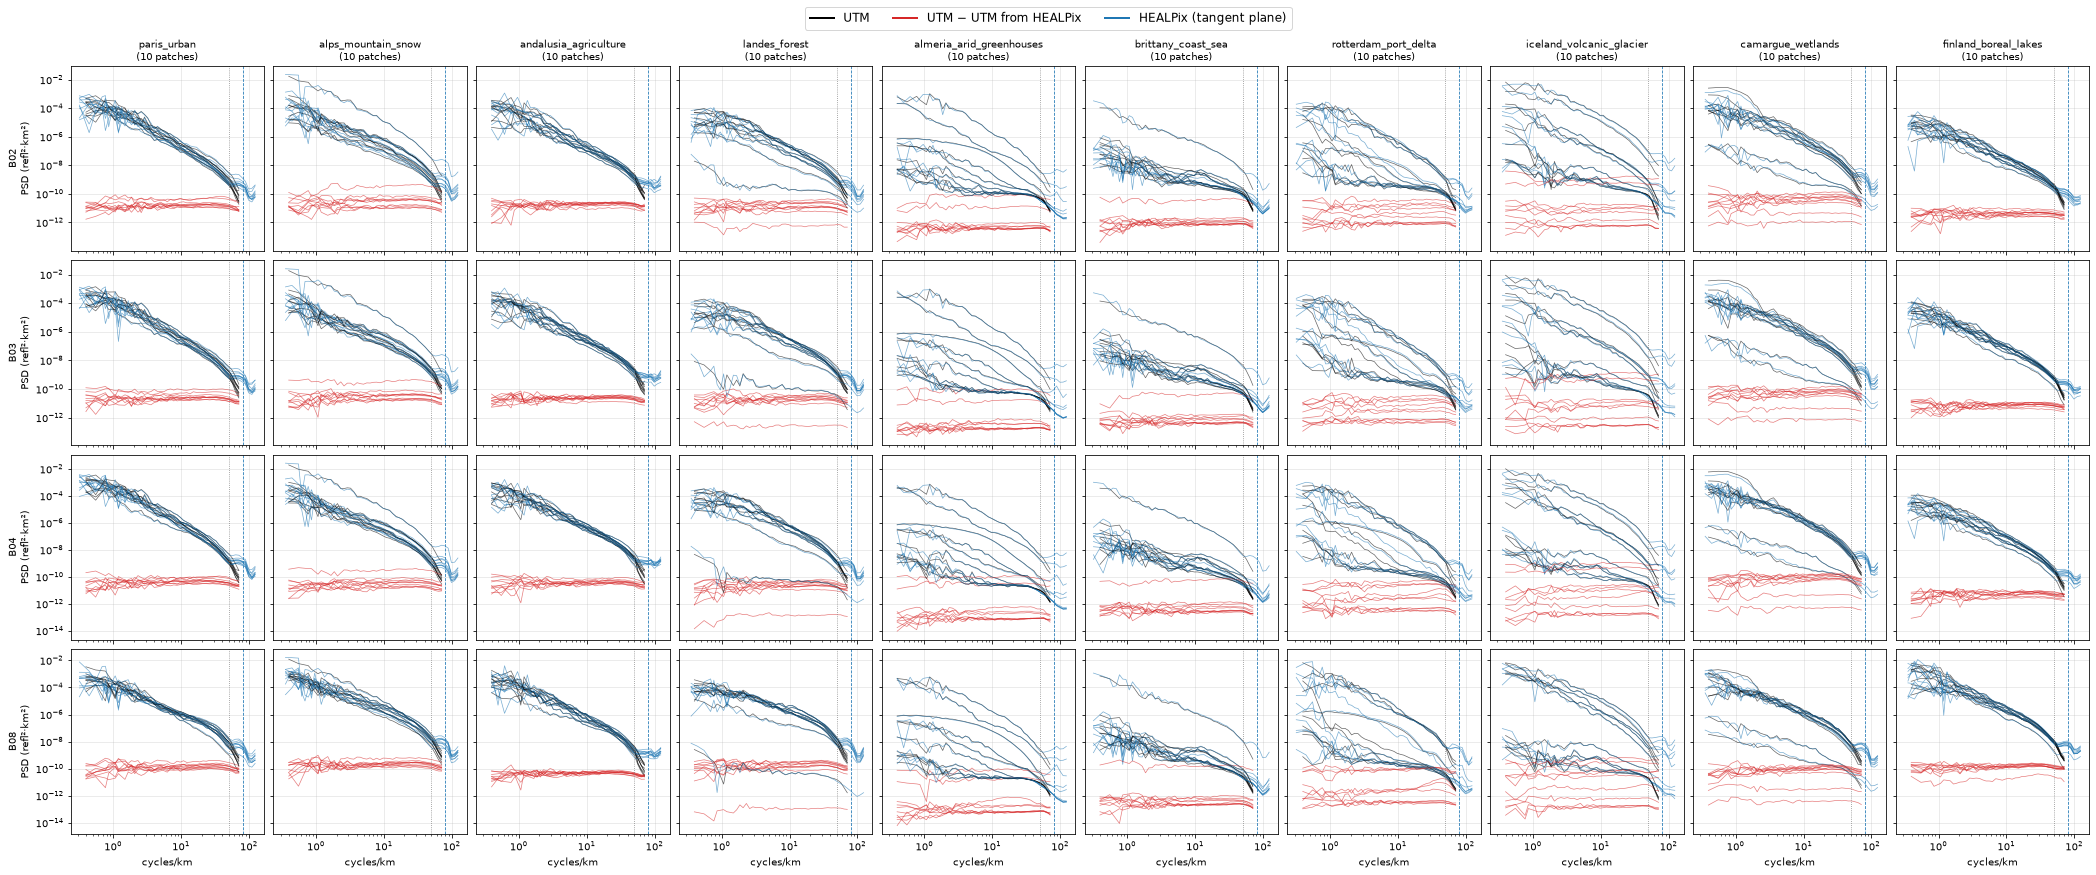

In [6]:
sites = [s for s in results if results[s]["patches"]]
COLORS = [("UTM", "k"), ("UTM − UTM from HEALPix", "C3"), ("HEALPix (tangent plane)", "C0")]
fig, ax = plt.subplots(len(BANDS), len(sites), figsize=(2.9 * len(sites), 2.9 * len(BANDS)),
                       sharex=True, sharey="row", constrained_layout=True, squeeze=False)
for c, site in enumerate(sites):
    P = results[site]["patches"]
    nyq_hpx = 1e3 / (2 * np.mean([p["cell_m"] for p in P]))
    for r, b in enumerate(BANDS):
        a = ax[r, c]
        for p in P:
            for kind, (lab, col) in enumerate(COLORS):
                y = p["spec"][r, kind]; m = np.isfinite(y)          # skip empty frequency bins
                a.loglog(KC[m], y[m], color=col, lw=0.7, alpha=0.6)
        a.axvline(50, color="gray", lw=0.8, ls=":"); a.axvline(nyq_hpx, color="C0", lw=0.8, ls="--")
        a.grid(True, which="major", alpha=0.3)
        if r == 0:
            a.set_title(f"{site}\n({len(P)} patches)", fontsize=10)
        if c == 0:
            a.set_ylabel(f"{b.upper()}\nPSD (refl²·km²)")
        if r == len(BANDS) - 1:
            a.set_xlabel("cycles/km")
fig.legend([Line2D([], [], color=col, lw=2) for _, col in COLORS], [lab for lab, _ in COLORS],
           loc="lower center", ncol=3, bbox_to_anchor=(0.5, 1.0), fontsize=12)
plt.show()

### Residual level per tile

Median over the patches of each tile, in units of 10⁻³ reflectance (1 unit = 10 DN): standard deviation of the UTM signal, RMS of `UTM − UTM from HEALPix`, and the ratio of the two.

In [7]:
hdr = "".join(f"{b.upper() + ' std':>10}{'rms':>7}{'ratio':>8}" for b in BANDS)
print(f"{'site':26s}{'n':>3}" + hdr)
for site in sites:
    P = results[site]["patches"]
    std = np.median([p["std"] for p in P], axis=0) * 1e3
    rms = np.median([p["rms"] for p in P], axis=0) * 1e3
    print(f"{site:26s}{len(P):3d}" + "".join(f"{s:10.2f}{r:7.2f}{s / r:8.0f}" for s, r in zip(std, rms)))

site                        n   B02 std    rms   ratio   B03 std    rms   ratio   B04 std    rms   ratio   B08 std    rms   ratio
paris_urban                10     41.94   0.42      99     54.73   0.51     107     92.46   0.65     141     65.91   1.25      53
alps_mountain_snow         10     33.88   0.60      57     33.66   0.59      57     42.11   0.61      70     85.15   1.50      57
andalusia_agriculture      10     27.57   0.45      62     37.28   0.48      78     53.07   0.60      88     62.71   0.70      90
landes_forest              10     18.03   0.35      51     24.52   0.45      55     34.90   0.47      74     57.54   1.35      43
almeria_arid_greenhouses   10      1.53   0.07      23      1.40   0.05      27      1.32   0.04      37      1.26   0.03      38
brittany_coast_sea         10      1.98   0.11      19      1.74   0.09      20      1.63   0.07      23      1.64   0.07      25
rotterdam_port_delta       10      7.91   0.22      36     11.24   0.22      52     10.53 

### Patch locations

The patches used above, drawn on the 60 m overview (yellow squares).

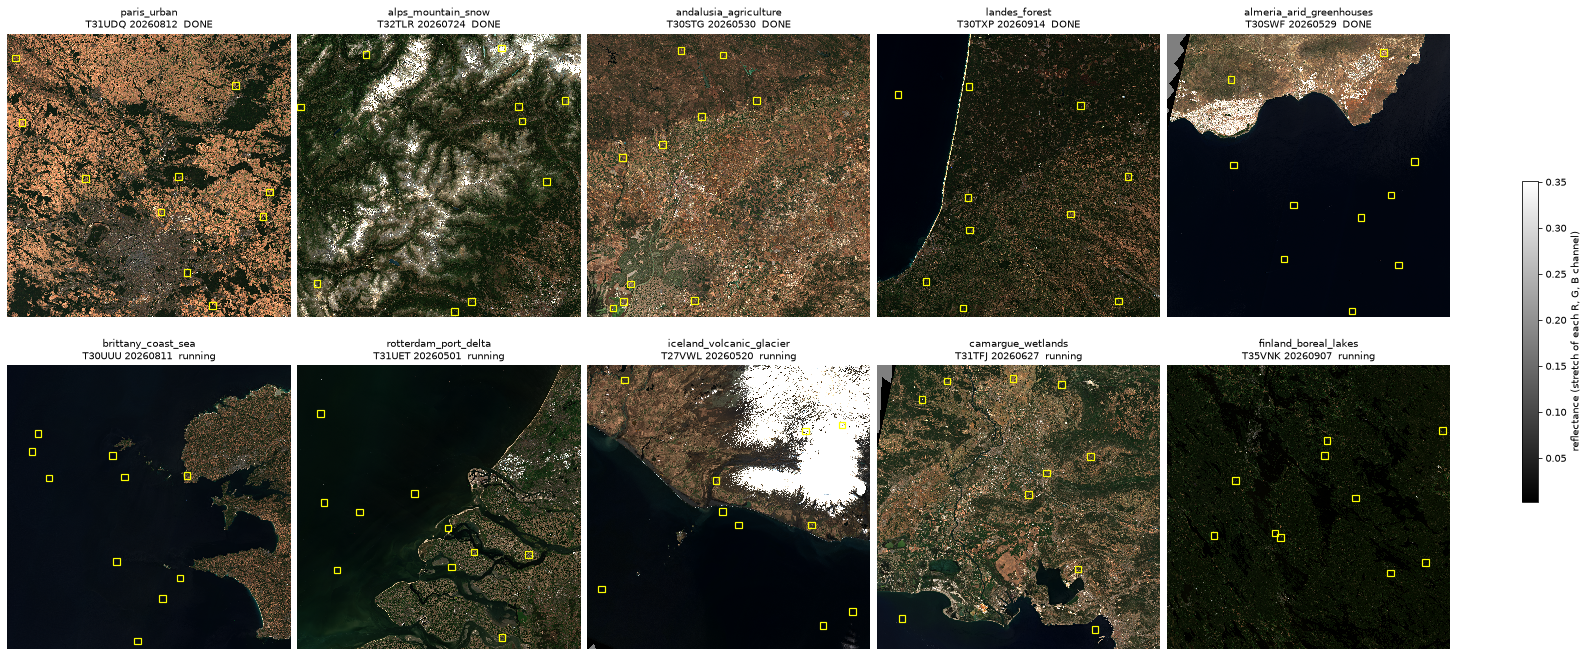

In [8]:
show_overview({s: [(p["i0"], p["j0"]) for p in results[s]["patches"]] for s in results})